# Spike train statistics
Poisson neurons: firing rates, ISIs, CV, binning and population bursts.

## 1. Simulate Poisson neurons

**Model.** Each neuron is a *homogeneous Poisson process*: it fires at random with a constant average rate $\lambda$ (spikes/s). The constant rate is the simplest assumption. It gives a clean baseline to compare real neurons against, since real neurons change their rate and burst.

**Inter-spike intervals (ISIs).** The ISI is the time between two consecutive spikes of the same neuron. If the neuron has the same small chance of firing at every instant and no memory of its last spike, the probability of waiting longer than $t$ without a spike is

$$P(\text{ISI} > t) = e^{-\lambda t}$$

so the ISIs follow an **exponential distribution**, $p(t) = \lambda e^{-\lambda t}$, with mean $1/\lambda$.

**Simulation.** For each neuron, we draw ISIs from this distribution and add them up (cumulative sum) to get spike times, keeping those inside the 60 s recording.

In [41]:
import numpy as np # numerical arrays and maths

rng = np.random.default_rng(42) # random generator with a fixed seed, so results are reproducible
T = 60.0 # recording length in seconds
rates = [2, 4, 6, 8, 10] # firing rate of each neuron in Hz

print(f"Recording length: {T} s") # show the settings
print(f"Rates (Hz): {rates}\n") # \n adds an empty line

spikes = [] # will hold one array of spike times per neuron
for r in rates: # loop over the 5 neurons
    n_spk = rng.poisson(r * T) # draw how many spikes the neuron fires in T seconds
    print(f"--- Neuron at {r} Hz ---")
    print(f"expected spikes (r*T): {r*T:.0f}, drawn: {n_spk}") # compare the expected and the random count

    t = np.sort(rng.uniform(0, T, n_spk)) # place the spikes at random times in [0, T], sorted
    print(f"first 5 spike times (s): {np.round(t[:5], 2)}") # peek at the start of the spike train
    print(f"last spike time (s): {t[-1]:.2f}") # should be just under 60 s

    spikes.append(t) # store this neuron's spike times
    print(f"first 10 spike times (s): {np.round(t[:10], 2)}\n") # t[:10] = only the first 10 values

print("spikes per neuron:", [len(s) for s in spikes]) # final count per neuron

Recording length: 60.0 s
Rates (Hz): [2, 4, 6, 8, 10]

--- Neuron at 2 Hz ---
expected spikes (r*T): 120, drawn: 129
first 5 spike times (s): [0.44 1.36 1.85 2.5  2.63]
last spike time (s): 58.54
first 10 spike times (s): [0.44 1.36 1.85 2.5  2.63 3.5  3.83 5.07 5.26 5.4 ]

--- Neuron at 4 Hz ---
expected spikes (r*T): 240, drawn: 268
first 5 spike times (s): [0.74 0.84 1.07 1.27 1.3 ]
last spike time (s): 59.54
first 10 spike times (s): [0.74 0.84 1.07 1.27 1.3  1.37 1.49 2.24 2.61 2.69]

--- Neuron at 6 Hz ---
expected spikes (r*T): 360, drawn: 392
first 5 spike times (s): [0.07 0.1  0.27 0.28 0.33]
last spike time (s): 59.95
first 10 spike times (s): [0.07 0.1  0.27 0.28 0.33 0.44 0.56 0.64 0.88 1.06]

--- Neuron at 8 Hz ---
expected spikes (r*T): 480, drawn: 470
first 5 spike times (s): [0.03 0.06 0.14 0.24 0.45]
last spike time (s): 59.97
first 10 spike times (s): [0.03 0.06 0.14 0.24 0.45 0.75 0.99 1.09 1.19 1.39]

--- Neuron at 10 Hz ---
expected spikes (r*T): 600, drawn: 599
fi

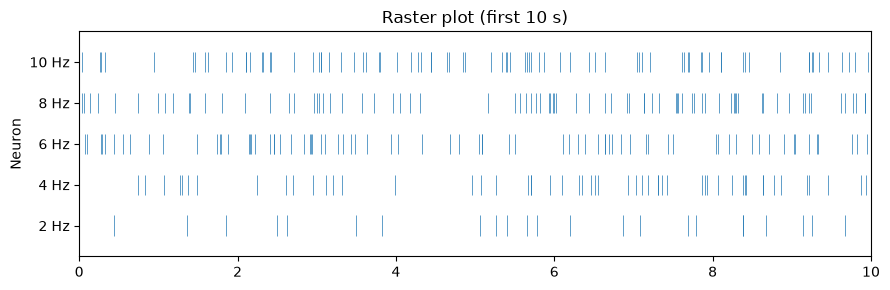

In [42]:
import matplotlib.pyplot as plt # plotting library

fig, ax = plt.subplots(figsize=(9, 3)) # one wide plot
ax.eventplot(spikes, lineoffsets=range(len(rates)), # one row per neuron, one tick per spike
             linelengths=0.5, linewidths=0.5)
ax.set_yticks(range(len(rates))) # one y-tick per neuron
ax.set_yticklabels([f"{r} Hz" for r in rates]) # label each row with its rate
zoom = min(10, T) # show at most the first 10 s, or the whole recording if it's shorter
ax.set_xlim(0, zoom) # zoom in, otherwise ticks overlap
ax.set_ylabel("Neuron")
ax.set_title(f"Raster plot (first {zoom:g} s)") # title follows the zoom; :g drops the useless ".0"
plt.tight_layout() # avoid overlapping labels
plt.show()

## 2. Firing rates

The firing rate is the number of spikes divided by the recording time:

$$\text{rate} = \frac{N_\text{spikes}}{T}$$

Because the spike count is random (Poisson), the measured rate (the neuron's average rate over a finite recording) fluctuates around the true rate (its average rate over an infinitely long time). The true rate can never be observed directly, so we report the measured rate together with its uncertainty.

**How big is the uncertainty?** For a Poisson distribution with mean $\mu$, the variance equals the mean, so the standard deviation (SD) is $\sqrt{\mu}$. The expected spike count is $\mu = \lambda T$, so:

$$\text{SD(count)} = \sqrt{\lambda T} \qquad \text{typical relative error} = \frac{\sqrt{\lambda T}}{\lambda T} = \frac{1}{\sqrt{\lambda T}}$$

Example: a 2 Hz neuron over 60 s has 120 expected spikes, SD ≈ 11 spikes, so a typical relative error of ±9.1%. The error is larger for slow neurons and short recordings.

**Three kinds of error:**

| Error | Formula | Question it answers | Needs the true rate? |
|---|---|---|---|
| Typical error | $1/\sqrt{\lambda T}$ | How big is the error usually? (theory) | Yes |
| Relative error | $(\text{measured} - \lambda)/\lambda$ | How wrong was *this* measurement? | Yes |
| Estimated error | $1/\sqrt{N_\text{spikes}}$ | Same question, estimated from the data | No |

With real data only the estimated error is available, so a rate is reported as measured ± estimated error (e.g. 2.15 Hz ± 8.8%). In a simulation we know $\lambda$ and can check all three.

**Fano factor.** Cut the recording into windows (e.g. 1 s), count the spikes in each window, and compare how much the counts vary with their average:

$$F = \frac{\text{Var(count)}}{\text{mean(count)}} \qquad \text{Var} = \text{average of the squared distances from the mean}$$

Squaring makes all distances positive and gives large jumps (bursts) a big weight.

Example with a mean of 2 spikes per window:
- Poisson-like counts 2, 1, 3, 2, 0, 4: squared distances 0, 1, 1, 0, 4, 4, so Var = 1.67 and $F \approx 0.8$ (close to 1).
- Bursty counts 0, 0, 8, 0, 2: squared distances 4, 4, 36, 4, 0, so Var = 9.6 and $F = 4.8$.

For a Poisson neuron $F = 1$ (variance = mean). $F > 1$ means burstier than random, $F < 1$ more regular. It is the count-based counterpart of the CV, which does the same for ISIs.

In [83]:
for r, s in zip(rates, spikes): # pair each true rate with its spike times
    n = len(s) # number of spikes of this neuron
    measured = n / T # spikes / seconds = rate in Hz
    err = 100 * (measured - r) / r # relative error: how far off we are, in % of the true rate (simulation only)
    typical = 100 / np.sqrt(r * T) # typical error from theory: 1/√(true count), in % (simulation only)
    estimated = 100 / np.sqrt(n) # estimated error from the data: 1/√(measured count), in % (real data too)
    print(f"true rate {r:>2} Hz | typical error ±{typical:.1f} % | "
          f"spikes {n:>3} | measured rate {measured:5.2f} Hz | relative error {err:+5.1f} % | "
          f"estimated error ±{estimated:.1f} %")

true rate  2 Hz | typical error ±9.1 % | spikes 129 | measured rate  2.15 Hz | relative error  +7.5 % | estimated error ±8.8 %
true rate  4 Hz | typical error ±6.5 % | spikes 268 | measured rate  4.47 Hz | relative error +11.7 % | estimated error ±6.1 %
true rate  6 Hz | typical error ±5.3 % | spikes 392 | measured rate  6.53 Hz | relative error  +8.9 % | estimated error ±5.1 %
true rate  8 Hz | typical error ±4.6 % | spikes 470 | measured rate  7.83 Hz | relative error  -2.1 % | estimated error ±4.6 %
true rate 10 Hz | typical error ±4.1 % | spikes 599 | measured rate  9.98 Hz | relative error  -0.2 % | estimated error ±4.1 %


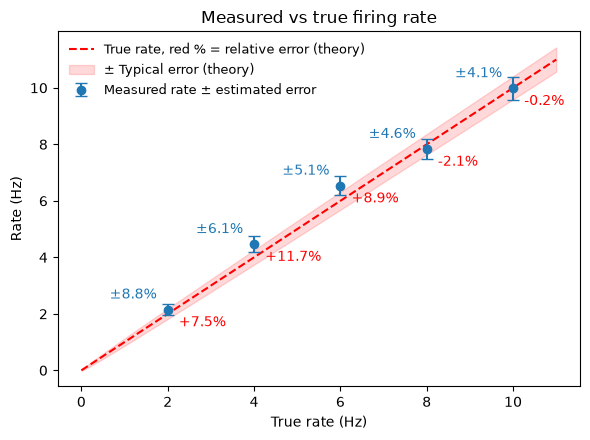

In [84]:
measured = [len(s) / T for s in spikes] # measured rate of each neuron (Hz)
counts = [len(s) for s in spikes] # spike count of each neuron
meas_err = [np.sqrt(n) / T for n in counts] # estimated error from the data itself: √(spike count) / T, in Hz
rel_err = [100 * (m - r) / r for m, r in zip(measured, rates)] # relative error of each neuron (%), needs the true rate

x = np.linspace(0, max(rates) * 1.1, 200) # 200 true rates from 0 to 10% above the fastest neuron, for a smooth line and band
band = np.sqrt(x * T) / T # typical error in Hz at each true rate: SD of the count / T

fig, ax = plt.subplots(figsize=(6, 4.5)) # one plot, a bit larger so all labels fit

# Simulation only (unknown in real data): red
ax.plot(x, x, "--", color="red", label="True rate, red % = relative error (theory)") # where a perfect measurement would land
ax.fill_between(x, x - band, x + band, color="red", alpha=0.15, # shaded band = true rate ± typical error
                label="± Typical error (theory)")
for r, m, e in zip(rates, measured, rel_err): # relative error: how wrong this measurement actually is
    ax.annotate(f"{e:+.1f}%", (r, m), textcoords="offset points", xytext=(8, -12), # below-right of the dot
                fontsize=10, color="red")

# Available in real data: blue
ax.errorbar(rates, measured, yerr=meas_err, fmt="o", capsize=4, color="tab:blue", # dots with vertical error bars
            label="Measured rate ± estimated error")
for r, m, n in zip(rates, measured, counts): # precision: how uncertain the measurement is, 1/√(spikes)
    ax.annotate(f"±{100 / np.sqrt(n):.1f}%", (r, m), textcoords="offset points", xytext=(-8, 8), # above-left of the dot
                ha="right", fontsize=10, color="tab:blue")

ax.set_xlabel("True rate (Hz)")
ax.set_ylabel("Rate (Hz)")
ax.set_title("Measured vs true firing rate")
ax.legend(frameon=False, fontsize=9, loc="upper left") # legend without a box, in the empty top-left corner
plt.tight_layout() # avoid overlapping labels
plt.show()